# 05 — Results: communities × content, sentiment over time, echo-chamber test, market comparison


We combine the components we previously produced in separate notebooks into a single location and answer the research questions.
1) First, we generate the sentiment profile for the three streams (equities, macro, and crypto).
2) Then, we profile what the 12 largest communities are discussing and how they feel.
3) Next, we juxtapose daily volume and negativity streaks with market events (Nvidia earnings, Jackson Hole, the employment report, CPI) and verify the true cause of the volume spikes using the day's defining keywords.

## 1. Load


In [1]:
import pickle
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from scipy.stats import pearsonr

RAW, PROC, FIG, SEED = "../data/raw", "../data/processed", "../figures", 42
content = pd.read_pickle(f"{PROC}/content.pkl")
nodes   = pd.read_csv(f"{PROC}/nodes_all.csv", index_col="did")
with open(f"{PROC}/graphs.pkl", "rb") as f:
    d = pickle.load(f)
graphs, giants = d["graphs"], d["giants"]
with open(f"{PROC}/communities.pkl", "rb") as f:
    louvain = pickle.load(f)["louvain"]
EMO = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]
STREAMS = ["equities", "macro", "crypto"]
handle_of = nodes.handle.to_dict()
content["community"] = content.community.astype("Int64")
print(content.shape, "| date range:", content.date.min(), "→", content.date.max())

(44958, 28) | date range: 2026-08-13 → 2026-09-13


## 2. Sentiment by stream and by post type


We calculate and compare the sentiment profiles of the three streams (equities, macro, crypto) using both RoBERTa and VADER; we also examine whether the posts identified via queries differ from the replies extracted from the threads.

In [2]:
# stream-level content analysis uses only the posts that matched a query (topical by construction);
# fetched thread replies can drift away from the topic, so they are used for the network and the community validation only
matched = content[content.source == "search"]
ex = matched.explode("streams").dropna(subset=["streams"]).rename(columns={"streams": "stream"})
print("query-matched posts:", len(matched), "| thread replies (not used here):", (content.source == "thread").sum())
def sent_profile(g):
    return pd.Series({"posts": len(g), "positive": (g.roberta_label == "positive").mean(), "neutral": (g.roberta_label == "neutral").mean(),
                      "negative": (g.roberta_label == "negative").mean(), "mean VADER": g.vader.mean(),
                      "VADER positive": (g.vader_label == "positive").mean(), "VADER negative": (g.vader_label == "negative").mean()})
by_stream = ex.groupby("stream").apply(sent_profile).loc[STREAMS]
by_type = content.groupby("source").apply(sent_profile).rename(index={"search": "query-matched posts", "thread": "thread replies"})
display(by_stream.round(3)); by_type.round(3)

query-matched posts: 24589 | thread replies (not used here): 20369


,posts,positive,neutral,negative,mean VADER,VADER positive,VADER negative
stream,,,,,,,
equities,7427.0,0.133,0.415,0.452,0.003,0.391,0.375
macro,7385.0,0.060,0.543,0.398,-0.026,0.376,0.403
crypto,9975.0,0.195,0.586,0.220,0.070,0.421,0.294


,posts,positive,neutral,negative,mean VADER,VADER positive,VADER negative
source,,,,,,,
query-matched posts,24589.0,0.136,0.521,0.343,0.021,0.398,0.351
thread replies,20369.0,0.128,0.410,0.463,0.031,0.398,0.335


The difference between the streams is distinct: 45.2% of equity posts are negative and 13.3% are positive; macro posts are 39.8% negative and only 6.0% positive, with the majority being neutral (54.3%); crypto, meanwhile, is the least pessimistic stream, with 22.0% negative and 19.5% positive posts (average VADER score of 0.070, compared to -0.026 for macro and 0.003 for equities). Thread replies are more negative than the original posts (46.3% vs. 34.3%), indicating that the tone hardens as the discussion deepens. VADER also identifies crypto as the least negative (29.4%) but swaps the ranking of equities and macro (macro at 40.3%, equities at 37.5%) and shows a smaller gap between the streams.

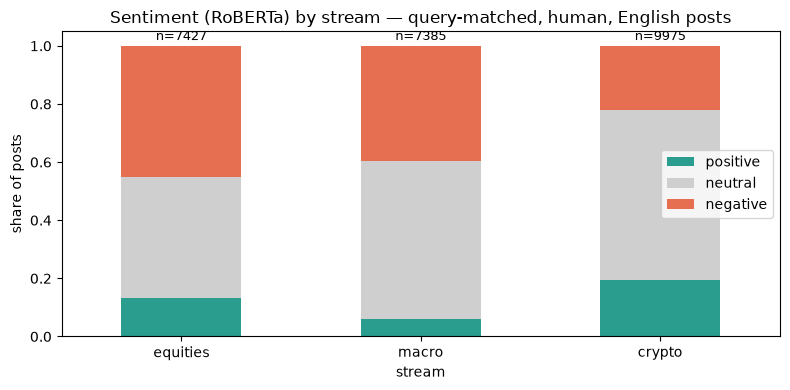

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
by_stream[["positive", "neutral", "negative"]].plot(kind="bar", stacked=True, ax=ax, color=["#2a9d8f", "#cfcfcf", "#e76f51"], rot=0)
ax.set_ylabel("share of posts"); ax.set_title("Sentiment (RoBERTa) by stream — query-matched, human, English posts")
for i, (s, row) in enumerate(by_stream.iterrows()):
    ax.text(i, 1.02, f"n={int(row.posts)}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/05_sentiment_by_stream.png", dpi=150); plt.show()

## 3. What do the communities talk about, and how do they feel?


We want to understand the Louvain communities not just in terms of numbers, but also in terms of content: who the central account of each community is, the number of posts and authors, the level of negativity, and which words and entities distinguish it from the others.

In [4]:
top_comms = nodes.community.value_counts().head(12).index.astype(int)
overall = Counter(w for ws in content.lemmas for w in ws); N = sum(overall.values())

def community_profile(c):
    g = content[content.community == c]
    cnt = Counter(w for ws in g.lemmas for w in ws); n = sum(cnt.values())
    # distinctive terms: frequent in the community and over-represented vs the whole corpus
    score = {w: (k / n) / (overall[w] / N) for w, k in cnt.items() if k >= 15}
    terms = ", ".join(w for w, _ in sorted(score.items(), key=lambda x: -x[1])[:8])
    ents = ", ".join(e for e, _ in Counter(e for es in g.entities_norm for e in es).most_common(5))
    hub = handle_of[max(nodes.index[nodes.community == c], key=lambda n: nodes.loc[n, "in_degree"])]
    return pd.Series({"hub": hub, "posts": len(g), "authors": g.author_did.nunique(), "negative": (g.roberta_label == "negative").mean(),
                      "positive": (g.roberta_label == "positive").mean(), "mean VADER": g.vader.mean(),
                      "distinctive terms": terms, "top entities": ents})
prof = pd.DataFrame({c: community_profile(c) for c in top_comms}).T
prof.index.name = "community"
pd.set_option("display.max_colwidth", 120)
prof.round(3)

,hub,posts,authors,negative,positive,mean VADER,distinctive terms,top entities
community,,,,,,,,
0,atrupar.com,939,633,0.504792,0.121406,0.009271,"fart, church, biden, lie, trillion, care, wait, shit","Trump, Fed, US, GOP, Biden"
1,carlquintanilla.bsky.social,2147,573,0.367955,0.110387,0.040771,"nixon, carter, appoint, reagan, reaction, powell, meeting, econsky","Fed, Warsh, Trump, US, Treasury"
2,peark.es,1663,403,0.388455,0.107035,0.022334,"productivity, vix, anthropic, pce, shock, credibility, function, reaction","Fed, Warsh, Trump, US, AI"
3,disabilitystor1.bsky.social,758,397,0.436675,0.175462,0.071589,"craig, princeton, doll, ethic, toy, professor, institute, teach","Fed, Bitcoin, Craig, Trump, US"
4,meidastouch.com,662,390,0.632931,0.067976,-0.101026,"govt, vote, canada, america, cause, trump, country, job","Fed, Trump, US, Warsh, GOP"
5,crampell.bsky.social,1006,370,0.418489,0.11332,0.027819,"casinos, best, york, cryptocurrency, xrp, kevin, threaten, live","Fed, Trump, US, Warsh, Bitcoin"
6,muellershewrote.com,417,293,0.693046,0.079137,-0.074,"dell, country, trump, low, way, job, want, interest","Trump, US, Fed, Biden, GOP"
7,sundaedivine.lol,526,264,0.585551,0.08365,0.023268,"rich, crash, talk, make, billion, war, cost, go","Fed, Trump, AI, US, Warsh"
8,andrewskeets.bsky.social,738,243,0.46477,0.165312,0.033215,"match, team, woman, fuck, guy, shit, lol, yeah","Fed, Kofi, ROH, Netflix, GCW"


The table shows that the communities differ by topic and by mood.
*  Economics communities are the calmest. C1 (carlquintanilla, CNBC) is the largest by content (2,147 posts, 573 authors) and the least negative (36.8%); its keywords (Nixon, Carter, Reagan, appoint, Powell) show a discussion about the history of Fed-chair appointments and political pressure on the Fed. C2 (peark.es, 1,663 posts, 38.8% negative) speaks the language of macro data (productivity, VIX, PCE, credibility). C5 (crampell, economics columnist, 41.8% negative) mixes markets and crypto (casinos, cryptocurrency, XRP).
* Political communities are the angriest. C6 (muellershewrote.com, 69.3% negative), C10 (angrystaffer, 68.2%) and C4 (meidastouch.com, 63.3%) talk about markets as politics (Trump, vote, govt, job, country) and are the only communities with a mean VADER score below zero. C0 (atrupar.com, the largest by authors: 633) sits in between at 50.5%, and C7 (sundaedivine, 58.6%) uses a general language of economic grievance (rich, crash, billion, war, cost).
*  Some communities are not about finance at all. C11 (kevinmkruse) and C3 (disabilitystor1) have the highest positive shares (18.2% and 17.5%), but their keywords (Princeton, professor, philosophy, college) describe academic threads that happen to hang from a keyword post. C8 (andrewskeets; match, team, ROH, GCW) is a wrestling residue and C9 (popbase.tv; actor, Gadot, movie) is about Gal Gadot's AI-generated Bitcoin film — the same topic that produces the 1 September peak in the timeline.
* The entities confirm the split: Fed, Trump and US are in the top five of almost every community, Warsh in five, Bitcoin in four. In short, the mood of the financial conversation depends more on which community you are in than on the news of the day: communities built around market reporters are informative, those built around political accounts are angry.

We want to see how communities differ from one another not only in terms of positive or negative sentiment, but also regarding eight basic emotions (anger, anticipation, disgust, fear, joy, sadness, surprise, and trust).

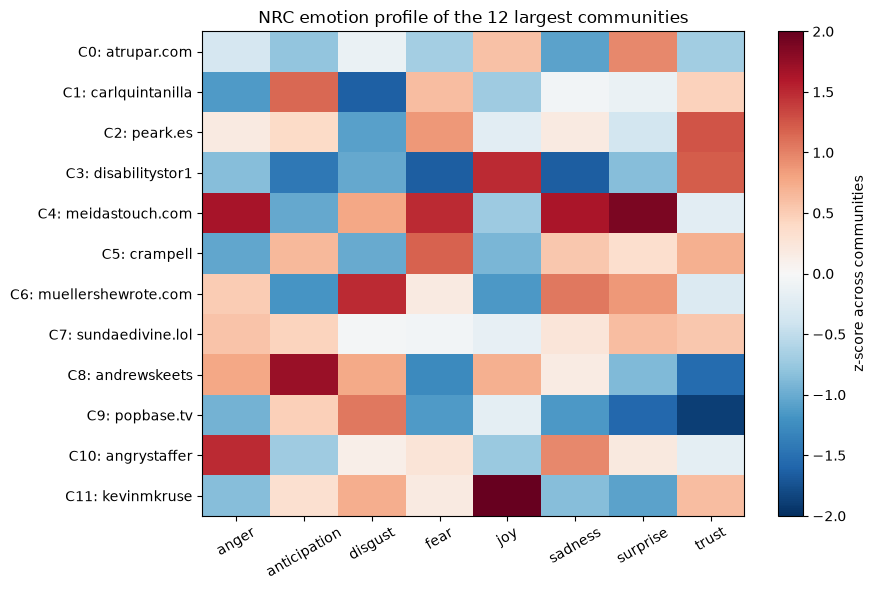

,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
community,,,,,,,,
0,0.043,0.070,0.034,0.055,0.049,0.040,0.063,0.099
1,0.037,0.087,0.021,0.070,0.037,0.046,0.050,0.116
2,0.047,0.080,0.026,0.073,0.042,0.047,0.047,0.127
3,0.039,0.064,0.026,0.043,0.058,0.036,0.041,0.127
4,0.059,0.067,0.041,0.080,0.037,0.056,0.075,0.106
5,0.038,0.082,0.026,0.077,0.035,0.050,0.056,0.119
6,0.050,0.066,0.047,0.065,0.033,0.053,0.062,0.105
7,0.050,0.080,0.034,0.062,0.042,0.048,0.059,0.117
8,0.052,0.092,0.041,0.048,0.051,0.047,0.040,0.087


In [5]:
# emotion profile per community (mean NRC share), shown as z-scores across communities
emo_c = content[content.community.isin(top_comms)].groupby("community")[EMO].mean().loc[top_comms]
z = (emo_c - emo_c.mean()) / emo_c.std()
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(EMO)), EMO, rotation=30); ax.set_yticks(range(len(top_comms)), [f"C{c}: {prof.loc[c,'hub'].replace('.bsky.social','')}" for c in top_comms])
plt.colorbar(im, label="z-score across communities"); ax.set_title("NRC emotion profile of the 12 largest communities")
plt.tight_layout(); plt.savefig(f"{FIG}/05_emotions_by_community.png", dpi=150); plt.show()
emo_c.round(3)

The emotion rates are small, but the pattern is consistent. The political communities carry the negative emotions: C4 (meidastouch) is highest in fear (0.080), anger (0.059), sadness (0.056) and surprise (0.075), C10 (angrystaffer) is close behind in anger (0.058), and C6 (muellershewrote) is highest in disgust (0.047). The market community C1 (carlquintanilla) stands out in anticipation (0.087) — the language of "what comes next"; only the off-topic wrestling community C8 scores higher (0.092). Joy is highest in the two academic threads, C11 (0.063) and C3 (0.058), and C3 also has the lowest fear and sadness. Trust is the most frequent emotion everywhere (0.082–0.127): highest in C2 (peark.es) and C3 (0.127), lowest in the off-topic C9 and C8, with the political communities below the middle (0.099–0.106).
* This matches the negativity ranking of the previous cell and says what kind of negativity it is: fear and anger in the political communities, anticipation in the market community.

## 4. Sentiment and volume over time, with market events


We are examining how the volume and tone of the conversation changed over the course of a month and whether four major market events are reflected in these series.

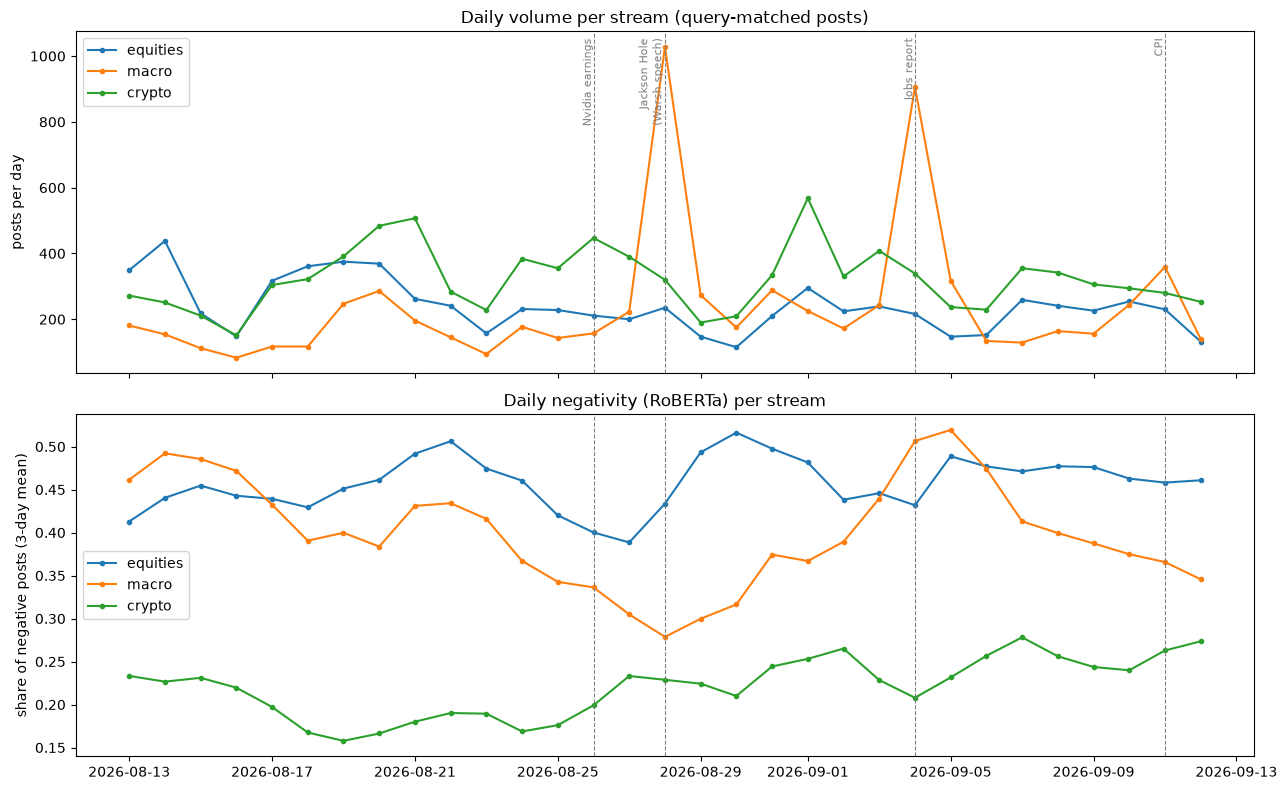

In [6]:
EVENTS = {"2026-08-26": "Nvidia earnings", "2026-08-28": "Jackson Hole\n(Warsh speech)", "2026-09-04": "Jobs report", "2026-09-11": "CPI"}
daily = (ex.groupby(["date", "stream"]).agg(posts=("uri", "size"), negative=("roberta_label", lambda s: (s == "negative").mean()),
                                            vader=("vader", "mean")).reset_index())
daily["date"] = pd.to_datetime(daily.date)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for s in STREAMS:
    g = daily[daily.stream == s].set_index("date")
    axes[0].plot(g.index, g.posts, marker=".", label=s)
    axes[1].plot(g.index, g.negative.rolling(3, center=True, min_periods=1).mean(), marker=".", label=s)
for d_, lab in EVENTS.items():
    for ax in axes: ax.axvline(pd.Timestamp(d_), color="grey", ls="--", lw=0.8)
    axes[0].text(pd.Timestamp(d_), axes[0].get_ylim()[1] * 0.98, lab, rotation=90, va="top", ha="right", fontsize=8, color="grey")
axes[0].set_ylabel("posts per day"); axes[0].legend(); axes[0].set_title("Daily volume per stream (query-matched posts)")
axes[1].set_ylabel("share of negative posts (3-day mean)"); axes[1].legend(); axes[1].set_title("Daily negativity (RoBERTa) per stream")
plt.tight_layout(); plt.savefig(f"{FIG}/05_timeline.png", dpi=150); plt.show()

The two macro spikes are Jackson Hole (28 Aug) and the jobs report (4 Sep); on those days the macro stream has about a thousand posts and all streams together 1,561 and 1,448 (next cell). The bottom panel shows that the order of the streams stays the same almost every day: equities and macro on top, crypto at the bottom. Negativity does not jump with the volume. Macro is actually at its lowest on the Jackson Hole day, because that day is mostly neutral reporting of the speech.

When interpreting volume spikes, instead of speculating, we identify the true cause of the spike by examining which words appear with unusual frequency in that day's posts.

In [7]:
# what drove the volume peaks? distinctive terms of a day vs the whole window
def day_terms(day, n=12, min_count=10):
    g = matched[matched.date == pd.Timestamp(day).date()]
    cnt = Counter(w for ws in g.lemmas for w in ws); tot = sum(cnt.values())
    score = {w: (k / tot) / (overall[w] / N) for w, k in cnt.items() if k >= min_count}
    return f"{len(g)} posts: " + ", ".join(f"{w} ({cnt[w]})" for w, _ in sorted(score.items(), key=lambda x: -x[1])[:n])
peaks = matched.groupby("date").size().nlargest(5).index
pd.Series({str(p): day_terms(p) for p in sorted(peaks)}).to_frame("distinctive terms")

,distinctive terms
2026-08-19,"1005 posts: unitree (27), humanoid (18), minutes (26), robotic (10), robotics (11), shanghai (13), robot (25), vanec..."
2026-08-20,"1134 posts: walmart (32), premarket (27), tumble (13), tapeboard (13), btcusd (30), clarity (35), urge (12), breakou..."
2026-08-28,"1561 posts: loved (11), elevate (41), jacksonhole (26), keynote (12), meaningfully (21), symposium (21), kevinwarsh ..."
2026-09-01,"1082 posts: gadot (106), movie (227), gal (121), godot (13), ndp (13), lighting (16), hong (15), kong (12), shein (1..."
2026-09-04,"1448 posts: threatens (13), slash (34), surplus (40), imf (22), halt (40), threaten (138), wash (12), jobs (11), sal..."


## 5. Do people reply to like-minded people? (homophily / echo-chamber test)


We test the question of whether people respond to individuals sharing their own emotional tone at two levels: network assortativity at the author level and parent-response polarity alignment at the response level.

In [8]:
# author-level sentiment: mean VADER of an author's posts, labelled with the same ±0.05 rule
auth_sent = content.groupby("author_did").agg(mean_vader=("vader", "mean"), n=("uri", "size"))
auth_sent["label"] = auth_sent.mean_vader.apply(lambda x: "positive" if x > 0.05 else ("negative" if x < -0.05 else "neutral"))
giant = giants["all"]
sub = giant.subgraph([n for n in giant.nodes() if n in auth_sent.index]).copy()
nx.set_node_attributes(sub, auth_sent.loc[list(sub.nodes()), "label"].to_dict(), "sent")
nx.set_node_attributes(sub, auth_sent.loc[list(sub.nodes()), "mean_vader"].round(1).to_dict(), "vader")
print("authors in the giant component with text:", sub.number_of_nodes(), "| edges:", sub.number_of_edges())
print("attribute assortativity (pos/neu/neg label):", round(nx.attribute_assortativity_coefficient(sub, "sent"), 3))
print("numeric assortativity (mean VADER, 1 decimal):", round(nx.numeric_assortativity_coefficient(sub, "vader"), 3))

# reply-level concordance: does a reply carry the same polarity as the post it answers?
replies = pd.read_pickle(f"{RAW}/replies_threads.pkl")[["uri", "parent_uri"]]
lab = content.set_index("uri").roberta_label
pairs = replies[replies.uri.isin(lab.index) & replies.parent_uri.isin(lab.index)]
same = (lab[pairs.uri].values == lab[pairs.parent_uri].values).mean()
p = lab.value_counts(normalize=True); expected = float((p ** 2).sum())
print(f"reply–parent same polarity: {same:.3f} vs {expected:.3f} expected if independent (n={len(pairs)} pairs)")
pd.crosstab(lab[pairs.parent_uri].values, lab[pairs.uri].values, rownames=["parent"], colnames=["reply"], normalize="index").round(3)

authors in the giant component with text: 10108 | edges: 11897
attribute assortativity (pos/neu/neg label): 0.042
numeric assortativity (mean VADER, 1 decimal): 0.075
reply–parent same polarity: 0.509 vs 0.397 expected if independent (n=21752 pairs)


reply,negative,neutral,positive
parent,,,
negative,0.560,0.346,0.094
neutral,0.375,0.507,0.118
positive,0.301,0.422,0.276


The giant component includes 10,108 authors and 11,897 reply links. Author-level assortativity is very low (0.042 for labels and 0.075 numerically), suggesting no clear echo chamber. However, replies match the sentiment of their parent posts 50.9% of the time, compared with 39.7% expected by chance. Negative posts are especially likely to receive negative replies (56.0%), while positive posts receive positive replies only 27.6% of the time. Overall, negativity spreads more strongly than positivity.

We are redrawing the community map from Notebook 03, this time coloring the nodes according to the author's average sentiment tone; we want to visualize in a single figure which communities are pessimistic and which are optimistic.

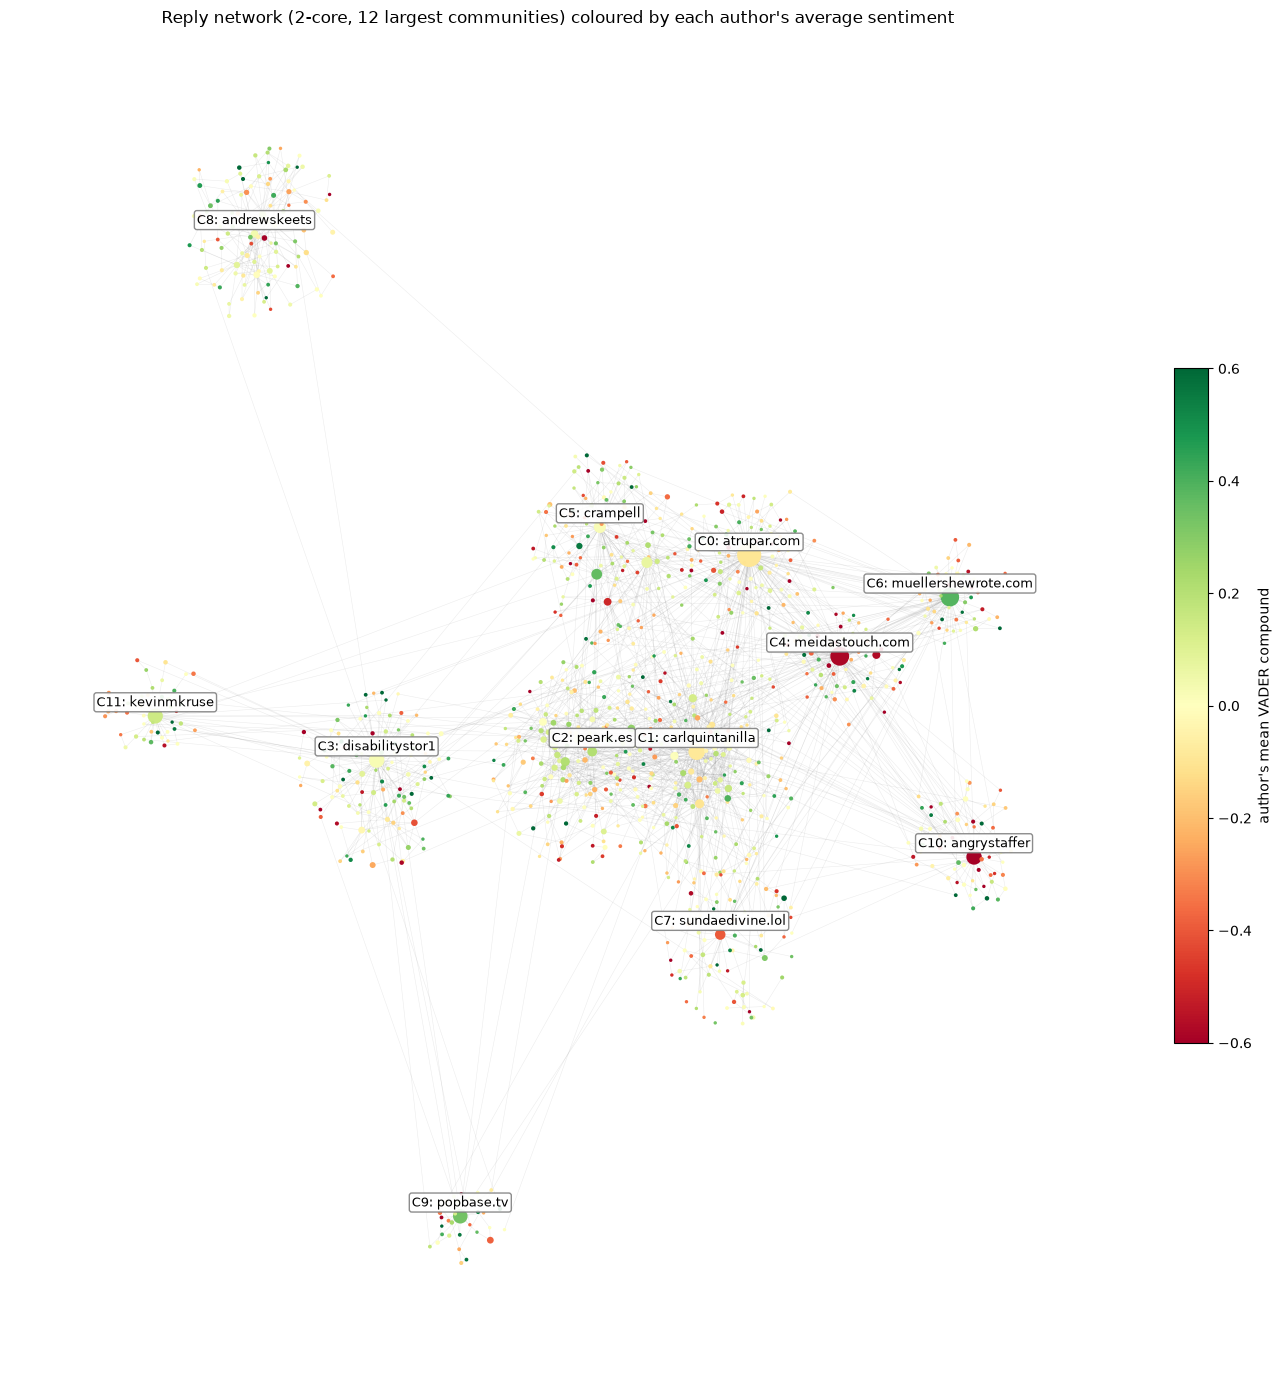

In [9]:
# fusion figure: the same 2-core layout idea, node colour = author's mean VADER
core = nx.k_core(giant, k=2)
core = core.subgraph([n for n in core.nodes() if n in auth_sent.index and louvain[n] in set(top_comms)]).copy()
comm_of = {n: louvain[n] for n in core.nodes()}
C = nx.Graph(); C.add_nodes_from(set(comm_of.values()))
for u, v in core.edges():
    if comm_of[u] != comm_of[v]:
        C.add_edge(comm_of[u], comm_of[v], weight=(C[comm_of[u]][comm_of[v]]["weight"] + 1) if C.has_edge(comm_of[u], comm_of[v]) else 1)
pos_C = nx.spring_layout(C, seed=SEED, weight="weight", k=2.5, scale=5)
sizes = pd.Series(comm_of).value_counts(); pos = {}
for c in C.nodes():
    members = [n for n in core.nodes() if comm_of[n] == c]
    local = nx.spring_layout(core.subgraph(members), seed=SEED, k=0.5) if len(members) > 1 else {members[0]: np.zeros(2)}
    r = 1.1 * np.sqrt(sizes[c] / sizes.max())
    for n, xy in local.items(): pos[n] = pos_C[c] + r * xy
vals = [auth_sent.loc[n, "mean_vader"] for n in core.nodes()]
indeg = dict(graphs["all"].in_degree())
fig, ax = plt.subplots(figsize=(14, 14))
nx.draw_networkx_edges(core, pos, alpha=0.15, width=0.4, edge_color="grey", ax=ax)
sc = nx.draw_networkx_nodes(core, pos, node_color=vals, cmap="RdYlGn", vmin=-0.6, vmax=0.6,
                            node_size=[6 + 1.5 * indeg.get(n, 0) ** 0.8 for n in core.nodes()], linewidths=0, ax=ax)
for c in C.nodes():
    hub = max((n for n in core.nodes() if comm_of[n] == c), key=lambda n: indeg.get(n, 0))
    ax.annotate(f"C{c}: {handle_of[hub].replace('.bsky.social','')}", pos[hub], fontsize=9, ha="center", xytext=(0, 7), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="grey", alpha=0.9))
plt.colorbar(sc, ax=ax, shrink=0.5, label="author's mean VADER compound")
ax.set_title("Reply network (2-core, 12 largest communities) coloured by each author's average sentiment", fontsize=12); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/05_network_sentiment.png", dpi=150); plt.show()

The map shows the 2-core of the twelve largest communities, laid out community by community, with each author coloured by the average VADER score of their own posts (green = positive, red = negative) and sized by the number of people who replied to them.
* Three things are visible. First, no community is one colour: every cluster mixes green, yellow and red dots, which is the picture behind the near-zero sentiment assortativity (0.04) — people do not sort themselves into positive and negative camps. Second, the tone of the hub is not the tone of its audience: the political hubs meidastouch (C4) and angrystaffer (C10) are deep red, while muellershewrote (C6) is green even though its community is the most negative one (69%) — its own posts use positive words, its repliers do not. The market hubs carlquintanilla (C1) and atrupar (C0) are pale yellow, i.e. neutral, reporting-style writing, and the economists around peark.es (C2) are light green. Third, the political communities on the right (C4, C6, C10) are visibly redder than the economics communities in the centre (C1, C2, C5), which matches the negativity ranking in the table above.
* The layout also shows the structure: the political and economics communities form one dense, interconnected core, while C8 (wrestling residue), C9 (popbase), C11 (kevinmkruse) and C3 (disabilitystor1) hang off it as satellites with only a handful of ties to the centre — off-topic conversations that entered the data through a single keyword post.

## 6. Does the conversation move with the market? (exploratory)


We are conducting an exploratory test using SPY (S&P 500 ETF) and Bitcoin data to determine whether daily volume and tone on Bluesky are associated with market movements on the same day and the following day.

In [10]:
import yfinance as yf
px = yf.download(["SPY", "BTC-USD"], start="2026-08-10", end="2026-09-14", auto_adjust=True, progress=False)
mkt = pd.DataFrame({"SPY_ret": px["Close"]["SPY"].pct_change(), "SPY_vol": px["Volume"]["SPY"],
                    "BTC_ret": px["Close"]["BTC-USD"].pct_change(), "BTC_vol": px["Volume"]["BTC-USD"]})
mkt.index = pd.to_datetime(mkt.index.date)

def stream_daily(s):
    g = daily[daily.stream == s].set_index("date")[["posts", "negative", "vader"]]
    return g.rename(columns=lambda c: f"{s}_{c}")
pairs = [("equities", "SPY"), ("crypto", "BTC")]
rows = []
for s, tk in pairs:
    m = stream_daily(s).join(mkt[[f"{tk}_ret", f"{tk}_vol"]], how="inner").dropna()
    m[f"{tk}_absret"] = m[f"{tk}_ret"].abs()
    for x, y in [(f"{s}_posts", f"{tk}_vol"), (f"{s}_posts", f"{tk}_absret"), (f"{s}_vader", f"{tk}_ret"), (f"{s}_negative", f"{tk}_ret")]:
        r0, p0 = pearsonr(m[x], m[y])
        r1, p1 = pearsonr(m[x].iloc[:-1].values, m[y].iloc[1:].values)     # social today vs market tomorrow
        rows.append({"stream": s, "social": x.split("_")[1], "market": y.split("_")[1], "n days": len(m),
                     "r same day": r0, "p": p0, "r (social t → market t+1)": r1, "p ": p1})
corr = pd.DataFrame(rows).round(3); corr

,stream,social,market,n days,r same day,p,r (social t → market t+1),p
0,equities,posts,vol,17,0.277,0.281,0.284,0.286
1,equities,posts,absret,17,-0.000,0.999,-0.002,0.994
2,equities,vader,ret,17,0.335,0.188,-0.541,0.030
3,equities,negative,ret,17,-0.593,0.012,0.230,0.391
4,crypto,posts,vol,31,0.701,0.000,0.482,0.007
5,crypto,posts,absret,31,0.580,0.001,0.231,0.219
6,crypto,vader,ret,31,0.432,0.015,0.289,0.122
7,crypto,negative,ret,31,-0.424,0.017,-0.390,0.033


We conduct an exploratory analysis using Bitcoin and SPY data to examine whether sentiment is related to same-day and next-day market movements. For Bitcoin, post activity is strongly associated with same-day trading volume (r=0.701, p<0.001) and absolute returns (r=0.580, p=0.001). Sentiment also tracks price movements: VADER correlates positively with returns (r=0.432, p=0.015), while negative sentiment correlates negatively (r=−0.424, p=0.017). This suggests that discussion increases with Bitcoin volatility and becomes more negative when prices fall.

For SPY, only negative sentiment is significantly related to same-day returns (r=−0.593, p=0.012); other same-day relationships are not significant. In the lagged analysis, SPY VADER is negatively associated with next-day returns (r=−0.541, p=0.030), but the sample includes only 17 trading days, so this should be treated cautiously. For Bitcoin, post count is associated with next-day volume (r=0.482, p=0.007), and negative sentiment with next-day returns (r=−0.390, p=0.033). However, lagged relationships are generally weaker than same-day ones and may partly reflect market autocorrelation. Therefore, these findings show associations rather than evidence that online discussion predicts market movements.

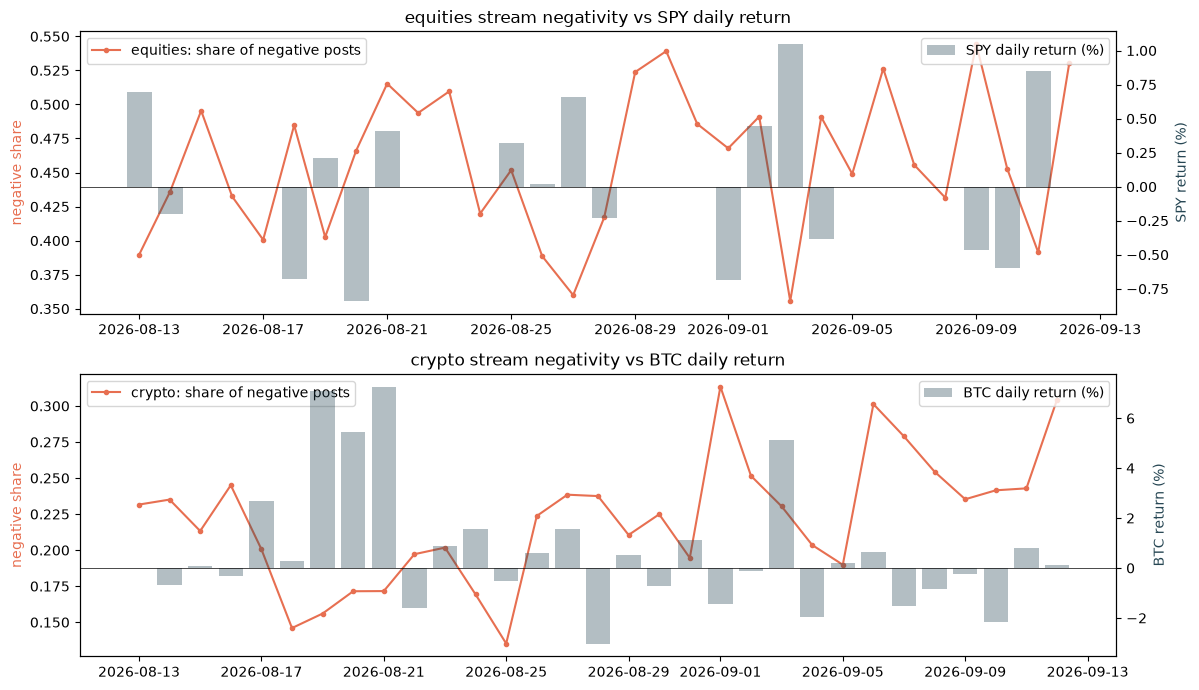

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (s, tk) in zip(axes, pairs):
    m = stream_daily(s).join(mkt, how="inner")
    ax.plot(m.index, m[f"{s}_negative"], color="#e76f51", marker=".", label=f"{s}: share of negative posts")
    ax.set_ylabel("negative share", color="#e76f51")
    ax2 = ax.twinx(); ax2.bar(m.index, m[f"{tk}_ret"] * 100, alpha=0.35, color="#264653", label=f"{tk} daily return (%)")
    ax2.set_ylabel(f"{tk} return (%)", color="#264653"); ax2.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{s} stream negativity vs {tk} daily return"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/05_market_vs_sentiment.png", dpi=150); plt.show()
corr.to_csv(f"{PROC}/market_correlations.csv", index=False); by_stream.round(4).to_csv(f"{PROC}/sentiment_by_stream.csv"); prof.to_csv(f"{PROC}/community_profiles.csv")